# Experiment 2C: Can modifying TuRBO-1's trust-region contraction and restart behaviour improve its ability to discover the better basin after unsuccessful early search?

All variants run from the start using paired seeds; this is not a conditional
continuation experiment like 2A. Existing rendered outputs are retained from
the saved run. The cells below resume the 600-trial checkpoint without rerunning
completed trials. New diagnostics use evaluation counts after each batch;
analysis corrects the earlier checkpoint's update timestamps in memory.

Keep this notebook beside `methods.ipynb` and `configurations.ipynb`. Dependency
installation is documented in the project README. Pilot and diagnostic cells
reuse the same checkpoint as the official sweep.


## Stage I: Initial trust-region size
Test whether a larger initial trust region helps TuRBO discover the better basin.

| Variant |	`length_init` | `failtol` |
| --- | --- | --- |
| Small region	| 0.4 |	4 |
| Default |	0.8 | 4 |
| Large region | 1.6 | 4 |

The initial trust-region length is measured in TuRBO's normalised coordinates.

**Hypothesis**: A larger initial trust region may help TuRBO sample farther from the inferior minimum, increasing discovery probability.

However, a large region might also make refinement less efficient.

## Stage II: Contraction sensitivity
Test how the number of consecutive failures before contraction changes discovery and restart behaviour.

| Variant |	`length_init` | `failtol` |
| --- | --- | --- |
| Fast contraction | 0.8 | 2 |
| Default |	0.8 | 4 |
| Slow contraction | 0.8 | 8 |
| Very slow contraction | 0.8 | 12 |

**Hypothesis**: Increasing `failtol` may prevent premature concentration, but could also delay beneficial restarts.

The default configuration appears in both stages, so there are only six unique configurations.

In [ ]:
from pathlib import Path
import time
from IPython.display import display
from scipy.stats import binomtest
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

code_dir = (
    Path("code")
    if Path("code/configurations.ipynb").is_file()
    else Path(".")
)

for filename in ("methods.ipynb", "configurations.ipynb"):
    notebook = json.loads(
        (code_dir / filename).read_text(encoding="utf-8")
    )
    for cell in notebook["cells"]:
        if cell["cell_type"] == "code":
            exec("".join(cell["source"]))

settings = EXPERIMENT_2C_SETTINGS

PENALTIES = settings["penalties"]
SEEDS = settings["main_seeds"]
BUDGET = settings["budget"]


In [2]:
VARIANTS = settings["variants"]
TURBO_PARAMS = {
    **METHOD_PARAMS["TuRBO-1"],
    "n_initial_points": settings["n_initial_points"],
}


## Implement loggable TuRBO

In [41]:
from turbo import Turbo1


class LoggedTurbo1(Turbo1):

    def __init__(self, *args, **kwargs):
        self.restart_events = []
        self.tr_history = []
        self.restart_count = 0
        super().__init__(*args, **kwargs)

    def _restart(self):
        # Do not count the initial setup as a restart
        if self.n_evals > 0:
            old_length = self.length
            self.restart_count += 1

            self.restart_events.append({
                "evaluation": int(self.n_evals),
                "length_before": float(old_length),
            })

        result = super()._restart()

        if self.n_evals > 0:
            self.tr_history.append({
                "evaluation": int(self.n_evals),
                "old_length": float(old_length),
                "new_length": float(self.length),
                "event": "restart",
            })

        return result

    def _adjust_length(self, fX_next):
        old_length = self.length

        super()._adjust_length(fX_next)

        self.tr_history.append({
            "evaluation": int(self.n_evals + len(fX_next)),
            "old_length": float(old_length),
            "new_length": float(self.length),
            "event": "update",
        })


## Revamped `run_turbo1` method

In [37]:
def run_turbo1(objective, bounds, budget, seed, params):
    import torch

    bounds = np.asarray(bounds)
    recorder = EvaluationResults(objective, budget)
    
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    optimiser = LoggedTurbo1(
        recorder, 
        bounds[:, 0], 
        bounds[:, 1],
        n_init=params["n_initial_points"], 
        max_evals=budget, 
        verbose=False,
    )

    for key in (
        "length_init",
        "length_min",
        "length_max",
        "failtol",
        "succtol",
    ):
        if key in params:
            setattr(optimiser, key, params[key])
    
    try:
        optimiser.optimize()
    except BudgetReached:
        pass
    return recorder.result(
        restart_events=optimiser.restart_events,
        restart_count=optimiser.restart_count,
        trust_region_history=optimiser.tr_history,
        trust_region_history_version=2,
    )

## Checkpoint setup

Load and validate saved trials before any optimisation.


In [ ]:
OUTPUT_PATH = code_dir / EXPERIMENT_2C_SETTINGS["checkpoint"]
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)


def load_results(path):
    """Read complete trials without counting duplicate appends twice."""
    if not path.exists():
        return []
    unique = {}
    with path.open(encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            if not line.strip():
                continue
            try:
                record = json.loads(line)
            except json.JSONDecodeError as error:
                raise ValueError(f"Invalid checkpoint JSON on line {line_number}; saved data was left untouched.") from error
            key = (record["c"], record["seed"], record["variant"])
            if key in unique:
                previous = unique[key]
                if any(previous.get(field) != record.get(field) for field in ("params", "X", "y")):
                    raise ValueError(f"Conflicting checkpoint trials for {key}; use a separate checkpoint for new settings.")
            else:
                unique[key] = record
    return list(unique.values())


def current_run(record):
    return (record["c"] in PENALTIES and record["seed"] in SEEDS
            and record["variant"] in VARIANTS)


cached_runs = {}
for record in load_results(OUTPUT_PATH):
    if not current_run(record):
        continue
    expected = {**TURBO_PARAMS, **VARIANTS[record["variant"]]}
    if (record["params"] != expected or len(record["y"]) != BUDGET
            or np.asarray(record["X"]).shape != (BUDGET, len(DOMAIN_BOUNDS))):
        raise ValueError("Checkpoint settings or budget differ; choose another OUTPUT_PATH to preserve the saved trials.")
    cached_runs[(record["c"], record["seed"], record["variant"])] = record


def get_or_run(c, seed, variant):
    key = (int(c), int(seed), variant)
    if key in cached_runs:
        return cached_runs[key]
    params = {**TURBO_PARAMS, **VARIANTS[variant]}
    start = time.perf_counter()
    result = run_turbo1(make_objective(c), DOMAIN_BOUNDS, BUDGET, seed, params)
    record = {
        "c": int(c), "seed": int(seed), "variant": variant, "params": params,
        "X": np.asarray(result["X"]).tolist(),
        "y": np.asarray(result["y"]).ravel().tolist(),
        "n_evaluations": len(result["y"]),
        "diagnostics": result["diagnostics"],
        "elapsed_seconds": time.perf_counter() - start,
    }
    if record["n_evaluations"] != BUDGET:
        raise ValueError(f"Incomplete trial {key}; it has not been marked complete.")
    with OUTPUT_PATH.open("a", encoding="utf-8") as file:
        file.write(json.dumps(record) + "\n")
    cached_runs[key] = record
    return record


print(f"Reusing {len(cached_runs)} completed trials from {OUTPUT_PATH}")


Reusing 600 completed trials from code\results\experiment2c_sweep.jsonl


## Pilot results

In [16]:
pilot_results = []
for c in PENALTIES:
    for seed in SEEDS[:settings["pilot_seed_count"]]:
        for name in VARIANTS:
            record = get_or_run(c, seed, name)
            y = np.asarray(record["y"])
            pilot_results.append({
                "c": c, "seed": seed, "variant": name,
                "best": float(y.min()),
                "discovered": bool(np.any(y < settings["discovery"])),
                "precise": bool(np.any(y < settings["precision"])),
                "n_evaluations": len(y),
            })
pilot_df = pd.DataFrame(pilot_results)
display(pilot_df.groupby(["c", "variant"])[["discovered", "precise", "best"]].mean())


discovered  precise      best
c  variant                                             
10 Default                       0.0      0.0  1.000483
   Fast contraction              0.0      0.0  1.001577
   Large region                  0.0      0.0  1.000648
   Slow contraction              0.0      0.0  1.001716
   Small region                  0.6      0.0  0.503211
   Very slow contraction         0.0      0.0  1.000810
30 Default                       0.0      0.0  1.000174
   Fast contraction              0.0      0.0  1.000867
   Large region                  0.0      0.0  1.000491
   Slow contraction              0.0      0.0  1.001564
   Small region                  0.2      0.0  0.809234
   Very slow contraction         0.0      0.0  1.000991

In [17]:
pilot_results

[{'c': 10,
  'seed': 100,
  'variant': 'Default',
  'best': 1.0004274743813302,
  'discovered': False,
  'precise': False,
  'n_evaluations': 50},
 {'c': 10,
  'seed': 100,
  'variant': 'Small region',
  'best': 0.34994827659553934,
  'discovered': True,
  'precise': False,
  'n_evaluations': 50},
 {'c': 10,
  'seed': 100,
  'variant': 'Large region',
  'best': 1.000133466351862,
  'discovered': False,
  'precise': False,
  'n_evaluations': 50},
 {'c': 10,
  'seed': 100,
  'variant': 'Fast contraction',
  'best': 1.0050640988751418,
  'discovered': False,
  'precise': False,
  'n_evaluations': 50},
 {'c': 10,
  'seed': 100,
  'variant': 'Slow contraction',
  'best': 1.0029196289996132,
  'discovered': False,
  'precise': False,
  'n_evaluations': 50},
 {'c': 10,
  'seed': 100,
  'variant': 'Very slow contraction',
  'best': 1.001898849450439,
  'discovered': False,
  'precise': False,
  'n_evaluations': 50},
 {'c': 10,
  'seed': 101,
  'variant': 'Default',
  'best': 1.0000912392065744

## Inspect one checkpointed trial


In [42]:
result = get_or_run(PENALTIES[0], SEEDS[0], "Small region")
print(result["diagnostics"])


{'restart_events': [{'evaluation': 42, 'length_before': 0.00625}], 'restart_count': 1, 'trust_region_history': [{'evaluation': 4, 'old_length': 0.4, 'new_length': 0.4, 'event': 'update'}, {'evaluation': 5, 'old_length': 0.4, 'new_length': 0.4, 'event': 'update'}, {'evaluation': 6, 'old_length': 0.4, 'new_length': 0.4, 'event': 'update'}, {'evaluation': 7, 'old_length': 0.4, 'new_length': 0.4, 'event': 'update'}, {'evaluation': 8, 'old_length': 0.4, 'new_length': 0.4, 'event': 'update'}, {'evaluation': 9, 'old_length': 0.4, 'new_length': 0.4, 'event': 'update'}, {'evaluation': 10, 'old_length': 0.4, 'new_length': 0.8, 'event': 'update'}, {'evaluation': 11, 'old_length': 0.8, 'new_length': 0.8, 'event': 'update'}, {'evaluation': 12, 'old_length': 0.8, 'new_length': 0.8, 'event': 'update'}, {'evaluation': 13, 'old_length': 0.8, 'new_length': 0.8, 'event': 'update'}, {'evaluation': 14, 'old_length': 0.8, 'new_length': 0.8, 'event': 'update'}, {'evaluation': 15, 'old_length': 0.8, 'new_leng

In [43]:
import pprint

pprint.pprint(result["diagnostics"])

{'restart_count': 1,
 'restart_events': [{'evaluation': 42, 'length_before': 0.00625}],
 'trust_region_history': [{'evaluation': 4,
                           'event': 'update',
                           'new_length': 0.4,
                           'old_length': 0.4},
                          {'evaluation': 5,
                           'event': 'update',
                           'new_length': 0.4,
                           'old_length': 0.4},
                          {'evaluation': 6,
                           'event': 'update',
                           'new_length': 0.4,
                           'old_length': 0.4},
                          {'evaluation': 7,
                           'event': 'update',
                           'new_length': 0.4,
                           'old_length': 0.4},
                          {'evaluation': 8,
                           'event': 'update',
                           'new_length': 0.4,
                           'old_length': 0.4

In [44]:
float(np.min(result["y"]))  # Best observed value, rather than the last evaluation.


0.34994827659553934

## Complete or resume the official sweep

Only missing trials run. Each completed trial is appended immediately, so an
interruption preserves all completed work. The pilot uses this same cache.


In [ ]:
before = len(cached_runs)
for c in PENALTIES:
    for seed in SEEDS:
        for name in VARIANTS:
            get_or_run(c, seed, name)
expected_runs = len(PENALTIES) * len(SEEDS) * len(VARIANTS)
print(f"Completed {len(cached_runs)}/{expected_runs} trials ({len(cached_runs) - before} new).")


Completed 600/600 trials (0 new).


In [67]:
RESULTS_PATH = OUTPUT_PATH
runs = [record for record in load_results(RESULTS_PATH) if current_run(record)]
print(f"Loaded {len(runs)} unique trials")


Loaded 600 unique trials


In [68]:
def first_hit(y, target):
    hits = np.flatnonzero(np.asarray(y) < target)
    return int(hits[0] + 1) if hits.size else None

## Build a trial-level DataFrame

In [70]:
def build_trials(runs, centre_a=BASIN_A, centre_b=BASIN_B,
                 near_a_radius=settings["near_a_radius"],
                 late_evaluations=settings["late_evaluations"]):

    a = np.asarray(centre_a)
    b = np.asarray(centre_b)

    rows = []

    for run in runs:
        X = np.asarray(run["X"])
        y = np.asarray(run["y"]).ravel()

        diagnostics = run.get("diagnostics", {})

        discovery = first_hit(y, settings["discovery"])
        precision = first_hit(y, settings["precision"])

        distance_a = np.linalg.norm(X - a, axis=1)
        distance_b = np.linalg.norm(X - b, axis=1)

        restarts = diagnostics.get("restart_events", [])
        restart_evals = [
            event["evaluation"] for event in restarts
        ]

        rows.append({
            "c": run["c"],
            "seed": run["seed"],
            "variant": run["variant"],

            "discovered": discovery is not None,
            "precise": precision is not None,

            "discovery_call": discovery,
            "precision_call": precision,

            "best": float(y.min()),
            "n_evaluations": len(y),

            "closest_b": float(distance_b.min()),
            "late_near_a": float(
                np.mean(distance_a[-late_evaluations:] <= near_a_radius)
            ),

            "restart_count": len(restarts),
            "first_restart": (
                restart_evals[0] if restart_evals else np.nan
            ),
        })

    return pd.DataFrame(rows)


In [71]:
trials = build_trials(runs)
display(trials.head())

,c,seed,variant,discovered,precise,discovery_call,precision_call,best,n_evaluations,closest_b,late_near_a,restart_count,first_restart
0,10,100,Default,False,False,NaN,NaN,1.000427,50,2.458878,0.95,1,49.0
1,10,100,Small region,True,False,50.0,NaN,0.349948,50,0.560150,0.60,1,42.0
2,10,100,Large region,False,False,NaN,NaN,1.000133,50,1.012499,0.60,1,42.0
3,10,100,Fast contraction,False,False,NaN,NaN,1.005064,50,1.051083,0.75,1,25.0
4,10,100,Slow contraction,False,False,NaN,NaN,1.002920,50,2.458878,1.00,0,NaN


In [72]:
def summarise_trials(trials):
    summary = trials.groupby(
        ["c", "variant"], sort=False
    ).agg(
        runs=("seed", "size"),
        discoveries=("discovered", "sum"),
        precision_successes=("precise", "sum"),
        discovery_rate=("discovered", "mean"),
        precision_rate=("precise", "mean"),
        median_best=("best", "median"),
        mean_best=("best", "mean"),
        mean_restarts=("restart_count", "mean"),
        mean_late_near_a=("late_near_a", "mean"),
    ).reset_index()

    for outcome, count_col in [
        ("discovery", "discoveries"),
        ("precision", "precision_successes"),
    ]:
        intervals = [
            binomtest(int(k), int(n)).proportion_ci(
                confidence_level=settings["confidence_level"],
                method="wilson"
            )
            for k, n in zip(
                summary[count_col], summary["runs"]
            )
        ]

        summary[f"{outcome}_ci_low"] = [
            ci.low for ci in intervals
        ]
        summary[f"{outcome}_ci_high"] = [
            ci.high for ci in intervals
        ]

    return summary


summary = summarise_trials(trials)
display(summary.round(3))

,c,variant,runs,discoveries,precision_successes,discovery_rate,precision_rate,median_best,mean_best,mean_restarts,mean_late_near_a,discovery_ci_low,discovery_ci_high,precision_ci_low,precision_ci_high
0,10,Default,50,12,9,0.24,0.18,1.000,0.782,0.60,0.674,0.143,0.374,0.098,0.308
1,10,Small region,50,20,10,0.40,0.20,1.000,0.630,0.90,0.579,0.276,0.538,0.112,0.330
2,10,Large region,50,12,10,0.24,0.20,1.000,0.780,0.52,0.705,0.143,0.374,0.112,0.330
3,10,Fast contraction,50,19,13,0.38,0.26,1.000,0.624,1.20,0.588,0.259,0.518,0.159,0.396
4,10,Slow contraction,50,10,9,0.20,0.18,1.001,0.803,0.00,0.798,0.112,0.330,0.098,0.308
5,10,Very slow contraction,50,11,9,0.22,0.18,1.001,0.783,0.00,0.776,0.128,0.352,0.098,0.308
6,30,Default,50,5,4,0.10,0.08,1.000,0.902,0.58,0.783,0.043,0.214,0.032,0.188
7,30,Small region,50,11,5,0.22,0.10,1.000,0.798,0.82,0.708,0.128,0.352,0.043,0.214
8,30,Large region,50,6,5,0.12,0.10,1.000,0.881,0.48,0.794,0.056,0.238,0.043,0.214
9,30,Fast contraction,50,14,9,0.28,0.18,1.000,0.723,1.16,0.588,0.175,0.417,0.098,0.308


In [73]:
def paired_comparisons(trials, outcome="discovered"):
    comparisons = []

    for c, group in trials.groupby("c"):
        paired = group.pivot(
            index="seed",
            columns="variant",
            values=outcome
        )

        if "Default" not in paired:
            continue
        for variant in paired.columns:
            if variant == "Default":
                continue

            pair = paired[["Default", variant]].dropna()
            if pair.empty:
                continue
            control = pair["Default"].astype(int)
            treatment = pair[variant].astype(int)

            delta = treatment - control

            comparisons.append({
                "c": c,
                "variant": variant,
                "pairs": len(delta),
                "gains": int((delta == 1).sum()),
                "losses": int((delta == -1).sum()),
                "difference": float(delta.mean()),
            })

    return pd.DataFrame(comparisons)


effects = paired_comparisons(trials)
display(effects)

,c,variant,pairs,gains,losses,difference
0,10,Fast contraction,50,10,3,0.14
1,10,Large region,50,5,5,0.00
2,10,Slow contraction,50,0,2,-0.04
3,10,Small region,50,9,1,0.16
4,10,Very slow contraction,50,1,2,-0.02
5,30,Fast contraction,50,10,1,0.18
6,30,Large region,50,2,1,0.02
7,30,Slow contraction,50,0,1,-0.02
8,30,Small region,50,6,0,0.12
9,30,Very slow contraction,50,0,1,-0.02


In [74]:
def build_tr_history(runs):
    rows = []

    for run in runs:
        diagnostics = run.get("diagnostics", {})
        events = diagnostics.get(
            "trust_region_history", []
        )

        for event in events:
            old = event.get("old_length", np.nan)
            new = event.get(
                "new_length",
                event.get("length", np.nan)
            )

            if event.get("event") == "restart":
                event_type = "restart"
            elif new < old:
                event_type = "contraction"
            elif new > old:
                event_type = "expansion"
            else:
                event_type = "unchanged"

            rows.append({
                "c": run["c"],
                "seed": run["seed"],
                "variant": run["variant"],
                # Legacy update events were logged before TuRBO advanced n_evals.
                # Restart timestamps already count completed evaluations.
                "evaluation": event["evaluation"] + (
                    1 if diagnostics.get("trust_region_history_version", 1) < 2
                    and event.get("event") == "update" else 0
                ),
                "old_length": old,
                "new_length": new,
                "event": event_type,
            })

    return pd.DataFrame(rows, columns=["c", "seed", "variant", "evaluation", "old_length", "new_length", "event"])


tr_history = build_tr_history(runs)

display(tr_history.head())


,c,seed,variant,evaluation,old_length,new_length,event
0,10,100,Default,5,0.8,0.8,unchanged
1,10,100,Default,6,0.8,0.8,unchanged
2,10,100,Default,7,0.8,0.8,unchanged
3,10,100,Default,8,0.8,0.8,unchanged
4,10,100,Default,9,0.8,0.8,unchanged


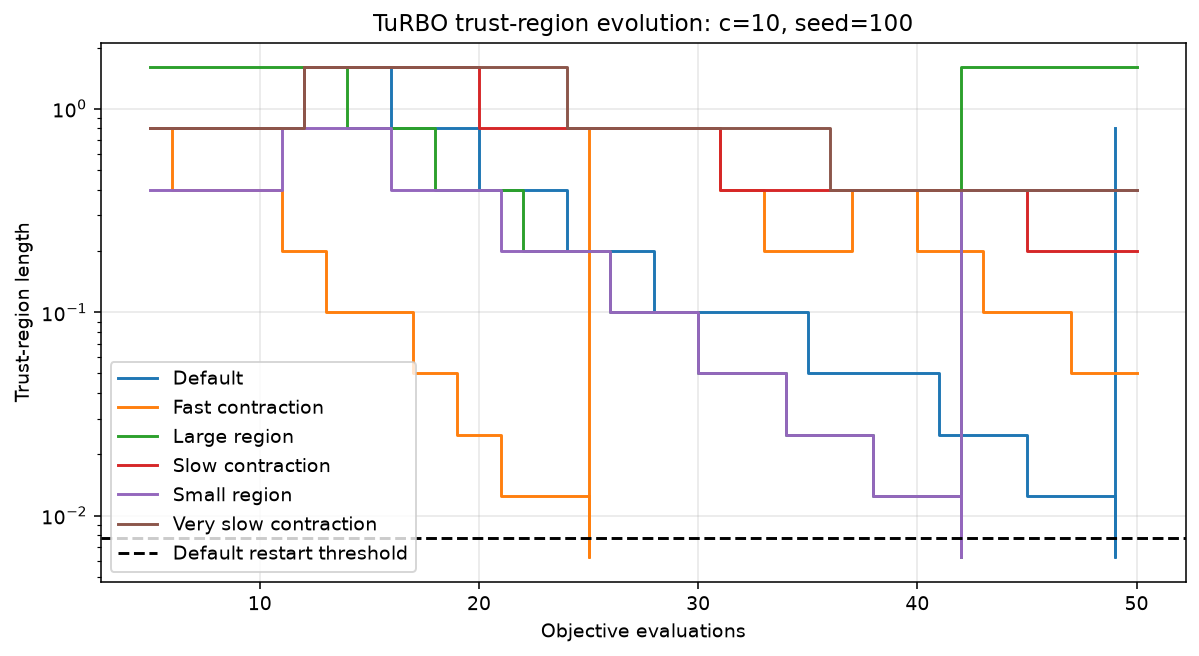

In [80]:
def plot_tr_length(tr_history, c, seed):
    subset = tr_history[
        (tr_history["c"] == c) &
        (tr_history["seed"] == seed)
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    for variant, group in subset.groupby("variant"):
        group = group.sort_values("evaluation")

        ax.step(
            group["evaluation"],
            group["new_length"],
            where="post",
            label=variant
        )

    ax.axhline(
        2**-7,
        color="black",
        linestyle="--",
        label="Default restart threshold"
    )

    ax.set(
        xlabel="Objective evaluations",
        ylabel="Trust-region length",
        title=f"TuRBO trust-region evolution: c={c}, seed={seed}"
    )

    ax.set_yscale("log")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.show()


plot_tr_length(tr_history, c=PENALTIES[0], seed=SEEDS[0])


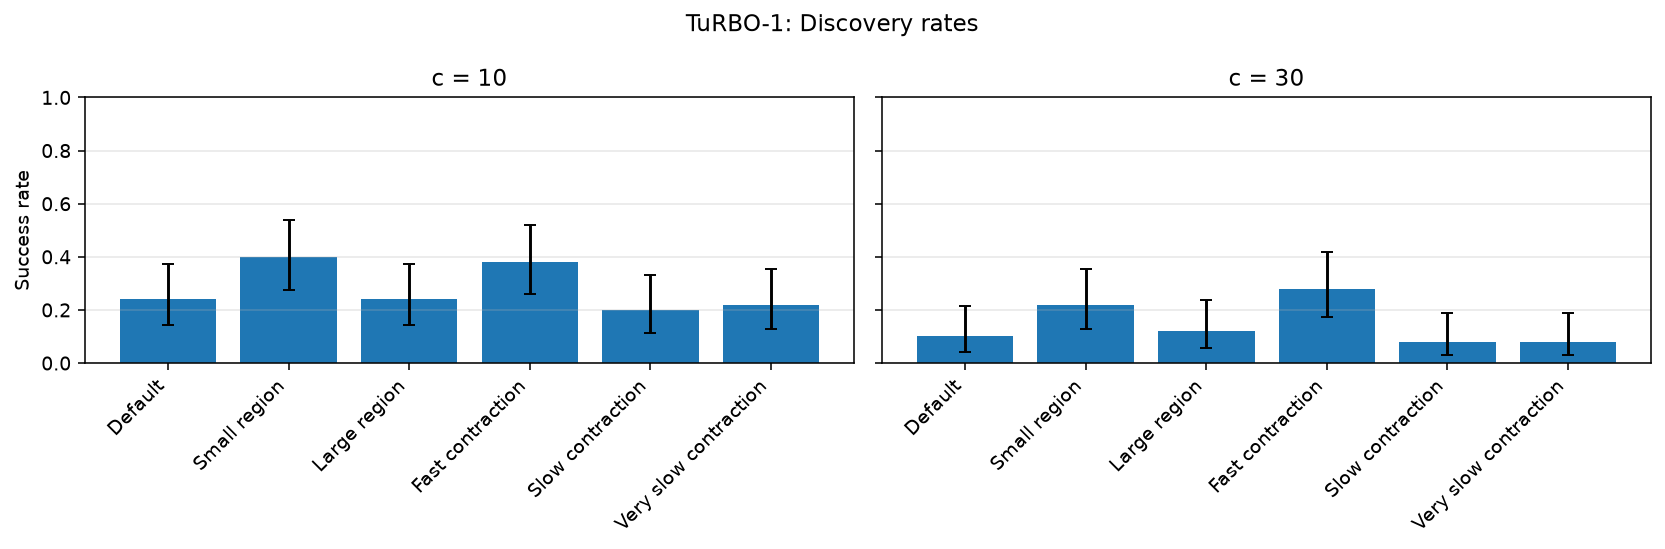

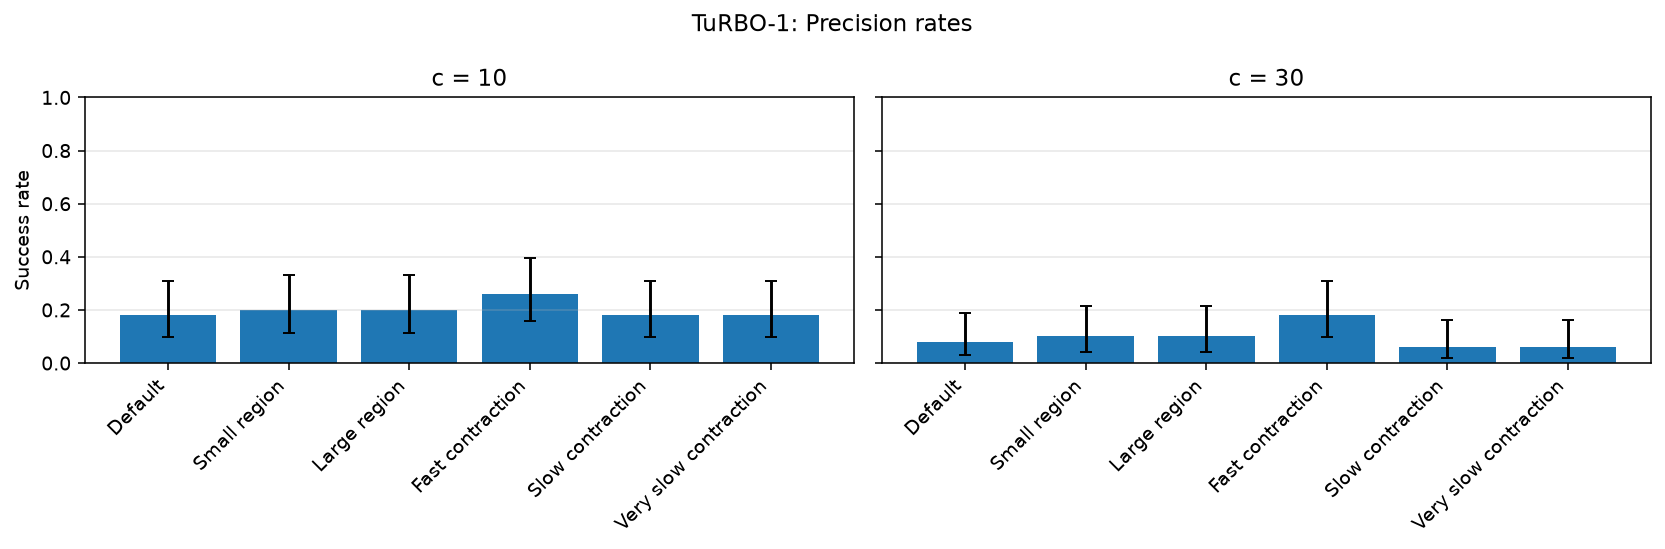

In [81]:
def plot_success_rates(summary, outcome="discovery"):
    rate_col = f"{outcome}_rate"
    low_col = f"{outcome}_ci_low"
    high_col = f"{outcome}_ci_high"

    penalties = sorted(summary["c"].unique())
    variants = list(summary["variant"].unique())

    fig, axes = plt.subplots(
        1, len(penalties),
        figsize=(6 * len(penalties), 4),
        sharey=True,
        squeeze=False
    )

    for ax, c in zip(axes.flat, penalties):
        subset = (
            summary[summary["c"] == c]
            .set_index("variant")
            .reindex(variants)
        )

        rates = subset[rate_col].to_numpy()
        lower = rates - subset[low_col].to_numpy()
        upper = subset[high_col].to_numpy() - rates

        ax.bar(
            range(len(variants)),
            rates,
            yerr=[lower, upper],
            capsize=3
        )

        ax.set_xticks(range(len(variants)))
        ax.set_xticklabels(variants, rotation=45, ha="right")
        ax.set_title(f"c = {c}")
        ax.set_ylim(0, 1)
        ax.grid(axis="y", alpha=0.3)

    axes[0, 0].set_ylabel("Success rate")
    fig.suptitle(f"TuRBO-1: {outcome.capitalize()} rates")
    fig.tight_layout()

    plt.show()


plot_success_rates(summary, "discovery")
plot_success_rates(summary, "precision")


In [82]:
summary["discoveries"] / summary["runs"]


0     0.24
1     0.40
2     0.24
3     0.38
4     0.20
5     0.22
6     0.10
7     0.22
8     0.12
9     0.28
10    0.08
11    0.08
dtype: float64

In [85]:
summary

,c,variant,runs,discoveries,precision_successes,discovery_rate,precision_rate,median_best,mean_best,mean_restarts,mean_late_near_a,discovery_ci_low,discovery_ci_high,precision_ci_low,precision_ci_high
0,10,Default,50,12,9,0.24,0.18,1.000254,0.781576,0.60,0.674,0.142974,0.374127,0.097702,0.307961
1,10,Small region,50,20,10,0.40,0.20,1.000094,0.630312,0.90,0.579,0.276084,0.538186,0.112438,0.330371
2,10,Large region,50,12,10,0.24,0.20,1.000291,0.779707,0.52,0.705,0.142974,0.374127,0.112438,0.330371
3,10,Fast contraction,50,19,13,0.38,0.26,1.000169,0.624338,1.20,0.588,0.258628,0.518496,0.158715,0.395532
4,10,Slow contraction,50,10,9,0.20,0.18,1.001394,0.803044,0.00,0.798,0.112438,0.330371,0.097702,0.307961
5,10,Very slow contraction,50,11,9,0.22,0.18,1.001210,0.783025,0.00,0.776,0.127539,0.352415,0.097702,0.307961
6,30,Default,50,5,4,0.10,0.08,1.000319,0.902352,0.58,0.783,0.043476,0.213602,0.031550,0.188382
7,30,Small region,50,11,5,0.22,0.10,1.000231,0.797637,0.82,0.708,0.127539,0.352415,0.043476,0.213602
8,30,Large region,50,6,5,0.12,0.10,1.000353,0.881016,0.48,0.794,0.056176,0.238048,0.043476,0.213602
9,30,Fast contraction,50,14,9,0.28,0.18,1.000298,0.723405,1.16,0.588,0.174742,0.416651,0.097702,0.307961


In [86]:
summary["precision_successes"] / summary["runs"]


0     0.18
1     0.20
2     0.20
3     0.26
4     0.18
5     0.18
6     0.08
7     0.10
8     0.10
9     0.18
10    0.06
11    0.06
dtype: float64